# LangChain 문서 MCP

https://docs.langchain.com/use-these-docs#quick-access-options



원격 서버 연결 방식

로컬에서 서버를 실행하지 않고, 이미 운영 중인 원격 MCP 서버에 HTTP/HTTPS로 연결합니다.

원격 서버 예시: LangChain 공식 문서 서버

안내 페이지: https://docs.langchain.com/use-these-docs

실제 MCP 서버 URL: https://docs.langchain.com/mcp

제공 기능: LangChain 문서 검색 및 조회


MultiServerMCPClient로 원격 서버 연결

# 세팅

In [1]:
! uv pip install langchain-mcp-adapters

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Audited 1 package in 2.62s


In [2]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("OPENAI API Key가 설정되었습니다.")

OPENAI API Key가 설정되었습니다.


# MCP Client agent 활용

## 간단 버전

실행 후 다음과 같은 질문을 시도해보세요:

랭체인에서 도구(툴) 만드는법 알려줘

랭체인의 create_agent 사용법(파이썬) 알려주세요.

랭체인을 처음 사용하는 사람이 읽으면 좋은 문서는?

langchain-openai 사용법 알려주세요.

In [5]:
# 여러 MCP 서버에 연결할 수 있는 클라이언트를 가져온다
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain.agents import create_agent

# "math" 서버에 HTTP 전송 방식으로 연결하는 클라이언트를 생성한다
client = MultiServerMCPClient(
    {
        "math": {
            "transport": "streamable_http",
            "url": "https://docs.langchain.com/mcp",
        }
    }
)

# 서버의 MCP 도구들을 LangChain 도구로 가져온다
tools = await client.get_tools()

# 도구를 사용하는 에이전트를 생성한다
agent = create_agent("openai:gpt-5-mini", tools)
# 에이전트에 질문을 전달하고 응답을 받는다
agent_response = await agent.ainvoke({"messages": " LangGraph의 특징에 대해 알려주세요"})

for m in agent_response["messages"]:
    m.pretty_print()

================================ Human Message =================================

 LangGraph의 특징에 대해 알려주세요
================================== Ai Message ==================================
Tool Calls:
  search_docs_by_lang_chain (call_KPC3ZDr8l1Acmv9Dg6uZcaIM)
 Call ID: call_KPC3ZDr8l1Acmv9Dg6uZcaIM
  Args:
    query: LangGraph 특징 LangGraph features
================================= Tool Message =================================
Name: search_docs_by_lang_chain

[{'type': 'text', 'text': 'Title: Acknowledgements\nLink: https://docs.langchain.com/oss/python/langgraph/overview#acknowledgements\nPage: oss/python/langgraph/overview\nContent: ## Acknowledgements\n\nLangGraph is inspired by [Pregel](https://research.google/pubs/pub37252/) and [Apache Beam](https://beam.apache.org/). The public interface draws inspiration from [NetworkX](https://networkx.org/documentation/latest/). LangGraph is built by LangChain Inc, the creators of LangChain, but can be used without LangChain.\n\n***\n\n<div 

## 도구 활용 확인 버전

In [6]:
# 여러 MCP 서버에 연결할 수 있는 클라이언트를 가져온다
from langchain_mcp_adapters.client import MultiServerMCPClient
# 도구를 사용하는 에이전트를 생성하는 함수를 가져온다
from langchain.agents import create_agent
# 응답 메시지의 타입을 판별하기 위해 메시지 클래스를 가져온다
from langchain_core.messages import AIMessage, ToolMessage

# "math"라는 이름으로 등록한 서버에 스트리밍 HTTP 전송 방식으로 연결하는 클라이언트를 생성한다
client = MultiServerMCPClient(
    {
        "math": {
            "transport": "streamable_http",
            "url": "https://docs.langchain.com/mcp",
        }
    }
)

# 원격 MCP 서버에 접속하여 서버가 제공하는 도구들을 LangChain 도구 객체로 가져온다
tools = await client.get_tools()

# 원격 서버에서 도구를 실제로 받아왔는지 확인한다 (도구 개수 출력)
print(f"[연결 확인] 원격 MCP 서버에서 가져온 도구 개수: {len(tools)}")
for t in tools:
    # 로드된 각 도구의 이름을 출력한다
    print(f"  - 로드된 도구 이름: {t.name}")

# 로드된 도구 이름을 집합으로 저장하여, 나중에 호출된 도구가 MCP 도구인지 대조한다
mcp_tool_names = {t.name for t in tools}

# 원격 MCP 서버에서 가져온 도구를 사용하는 에이전트를 생성한다
agent = create_agent("openai:gpt-5-mini", tools)

# 이번 실행에서 원격 MCP 도구가 실제로 호출되었는지 여부를 저장할 변수
used_remote_mcp = False


[연결 확인] 원격 MCP 서버에서 가져온 도구 개수: 3
  - 로드된 도구 이름: search_docs_by_lang_chain
  - 로드된 도구 이름: query_docs_filesystem_docs_by_lang_chain
  - 로드된 도구 이름: submit_feedback


In [7]:
# stream_mode=["updates", "messages"]로 두 종류의 스트림을 동시에 받는다
# - "messages": LLM이 생성하는 토큰을 실시간으로 흘려보낸다 (실시간 텍스트 출력용)
# - "updates" : 각 노드 실행이 끝날 때마다 완성된 메시지를 보낸다 (도구 사용 판정용)
async for mode, chunk in agent.astream(
    {"messages": " LangGraph의 특징에 대해 알려주세요"},
    stream_mode=["updates", "messages"],
):
    # 토큰 단위 스트림인 경우: (토큰, 메타데이터) 튜플이 들어온다
    if mode == "messages":
        # chunk를 토큰과 메타데이터로 분리한다
        token, metadata = chunk
        # 도구 실행 결과(ToolMessage)가 아니고 실제 텍스트 내용이 있으면 실시간으로 출력한다
        if token.content and not isinstance(token, ToolMessage):
            # 줄바꿈 없이 이어붙여 출력하고 즉시 화면에 반영한다
            print(token.content, end="", flush=True)

    # 노드 단위 스트림인 경우: {노드이름: {상태키: 값}} 형태의 딕셔너리가 들어온다
    elif mode == "updates":
        # 각 노드가 갱신한 메시지들을 순회하며 도구 사용 흔적을 검사한다
        for node_name, node_update in chunk.items():
            # 해당 노드가 반환한 메시지 목록을 꺼낸다 (없으면 빈 리스트)
            for m in node_update.get("messages", []):
                # 모델이 도구 호출을 요청한 메시지인지 확인한다
                if isinstance(m, AIMessage) and m.tool_calls:
                    for call in m.tool_calls:
                        # 호출한 도구가 원격 MCP 서버에서 로드한 도구인지 대조한다
                        if call["name"] in mcp_tool_names:
                            # 원격 MCP 도구 호출이 확인되었으므로 플래그를 설정한다
                            used_remote_mcp = True
                            # 실시간 텍스트와 섞이지 않도록 줄바꿈 후 호출 정보를 출력한다
                            print(f"\n[호출 감지] MCP 도구 호출: {call['name']} / 인자: {call['args']}")
                # 도구 실행 결과가 돌아온 메시지인지 확인한다
                if isinstance(m, ToolMessage) and m.name in mcp_tool_names:
                    # 원격 MCP 도구가 실제로 실행되었으므로 플래그를 설정한다
                    used_remote_mcp = True
                    # 어떤 도구의 결과가 수신되었는지 출력한다
                    print(f"\n[실행 결과] MCP 도구 '{m.name}'의 실행 결과를 수신함")

# 스트리밍이 끝난 뒤, 이번 응답에서 원격 MCP 서버 도구가 사용되었는지 최종 출력한다
print(f"\n[판정] 이번 응답에서 원격 MCP 서버 도구 사용 여부: {used_remote_mcp}")


[호출 감지] MCP 도구 호출: search_docs_by_lang_chain / 인자: {'query': 'LangGraph features LangGraph documentation'}

[실행 결과] MCP 도구 'search_docs_by_lang_chain'의 실행 결과를 수신함
요약하면 LangGraph는 장기 실행(stateful), 상태 보존이 필요한 에이전트(agents)와 워크플로우를 오케스트레이션하기 위한 저수준 런타임/프레임워크입니다. 주요 특징은 다음과 같습니다.

- 에이전트 오케스트레이션에 특화  
  - 모델/툴 호출의 높은 수준 추상화보다는 실행·조정·배포(오케스트레이션) 관점에 집중합니다.  
  - LangChain의 모델·툴과 함께 쓸 수 있지만 독립적으로 사용 가능.

- 장기 실행·내구성(durable execution) 지원  
  - 장시간 동작하는 작업(예: 이메일 처리, 장기 프로세스)과 상태(체크포인트)를 안전하게 저장·복구할 수 있음.  
  - 체크포인터(checkpointer) 설정(직렬화 옵션, TTL 등) 제공.

- 스트리밍 및 실시간 응답 처리  
  - 중간 결과를 스트리밍으로 전송해 사용자/시스템에 실시간 피드백을 줄 수 있음.

- Human-in-the-loop(사람 개입) 워크플로우 지원  
  - 자동화 중 특정 단계에서 사람의 승인·수정·결정을 끼워 넣을 수 있음.

- 저장소(BaseStore) 및 영구성, 검색 기능  
  - 내장 DB 기반 스토어, 문서 저장·검색 지원.  
  - Semantic search(임베딩 기반 검색) 설정 가능(임베딩 모델 지정·필드 지정 등).  
  - 항목 TTL, 읽기 시 TTL 갱신 등 세부 정책 설정 가능.

- 확장성·커스터마이징 옵션 풍부  
  - 커스텀 임베딩 함수, 체크포인터 serde(허용 모듈 목록, pickle fallback 등) 지원.  
  - langgraph.json으로 배포·스토어·체크포인트·웹훅·HTTP 설정 등

# LangGraph 활용 

In [9]:
from langchain_mcp_adapters.client import MultiServerMCPClient
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.prebuilt import ToolNode, tools_condition
from langchain.chat_models import init_chat_model
from langchain.messages import SystemMessage


model = init_chat_model("openai:gpt-5.4-mini")

# 원격 MCP 서버(LangChain 공식 문서)에서 Tools 로드
client = MultiServerMCPClient(
    {
        "langchain-docs": {
            "url": "https://docs.langchain.com/mcp",
            "transport": "http",
        }
    }
)
tools = await client.get_tools()          # 주피터 top-level await
print(f"사용 가능한 Tools: {[t.name for t in tools]}")

사용 가능한 Tools: ['search_docs_by_lang_chain', 'query_docs_filesystem_docs_by_lang_chain', 'submit_feedback']


In [10]:
# LLM 노드: 시스템 지침 + 대화 메시지로 응답 생성 (필요 시 Tool 호출 결정)
def call_model(state: MessagesState):
    system_message = SystemMessage(
        content="""당신은 LangChain 공식 문서를 기반으로 질문에 답변하는 AI 어시스턴트입니다.
문서 검색 도구를 사용해 정확한 정보를 제공하고, 답변에는 출처 url을 포함하며 한국어로 설명하세요."""
    )
    # 매 호출마다 시스템 메시지를 앞에 붙여 전달
    response = model.bind_tools(tools).invoke([system_message] + state["messages"])
    return {"messages": response}

# 그래프 구성: call_model ↔ tools 반복
builder = StateGraph(MessagesState)
builder.add_node(call_model)                       # 노드명 = 함수명 "call_model"
builder.add_node(ToolNode(tools))                  # 노드명 = 기본값 "tools"
builder.add_edge(START, "call_model")
builder.add_conditional_edges("call_model", tools_condition)  # tool_calls 있으면 "tools", 없으면 종료
builder.add_edge("tools", "call_model")            # Tool 실행 후 다시 LLM으로
graph = builder.compile()

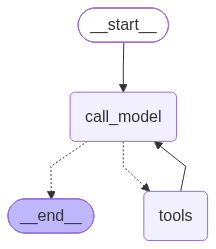

In [11]:
graph 

In [12]:
# stream_mode="messages": LLM 토큰을 (토큰, 메타데이터) 튜플로 실시간 스트리밍
async for msg, metadata in graph.astream(
    {"messages": "LangGraph의 특징을 알려주세요."},   # 질문은 이 문자열만 바꾸면 됨
    stream_mode="messages",
):
    # call_model 노드의 토큰만 즉시 출력 (tools 노드의 검색 원문은 제외)
    if msg.content and metadata.get("langgraph_node") == "call_model":
        print(msg.content, end="", flush=True)

LangGraph의 핵심 특징은 **장기 실행·상태 유지가 필요한 에이전트/워크플로를 위한 저수준 오케스트레이션 런타임**이라는 점입니다. 공식 문서 기준으로 보면 다음이 가장 중요합니다.

1. **Durable execution(내구성 있는 실행)**  
   실행 도중 장애가 나도 체크포인트를 통해 중단 지점부터 재개할 수 있습니다.  
   - 출처: https://docs.langchain.com/oss/python/langgraph/overview  
   - 관련 설명: https://docs.langchain.com/oss/python/langgraph/persistence

2. **Stateful workflow 지원**  
   단발성 호출이 아니라, 대화 맥락이나 중간 상태를 유지하는 그래프를 만들 수 있습니다.  
   - 출처: https://docs.langchain.com/oss/python/langgraph/overview

3. **Human-in-the-loop 지원**  
   특정 시점에 사람의 검토/수정/승인을 끼워 넣을 수 있습니다.  
   - 출처: https://docs.langchain.com/oss/python/langgraph/overview  
   - 관련: https://docs.langchain.com/oss/python/langchain/human-in-the-loop

4. **Persistence(지속 저장) 체계**  
   LangGraph는 두 가지 저장 방식을 제공합니다.  
   - **Checkpointers**: thread 단위의 그래프 상태를 체크포인트로 저장  
   - **Stores**: thread를 넘어서는 장기 기억 저장  
   - 출처: https://docs.langchain.com/oss/python/langgraph/persistence

5. **Streaming 지원**  
   복잡한 에이전트 실행 과정을 스트리밍 형태로 관찰할 수 있습니다.  
   - 